# Test de la fonction kws_compute_log_mel() dans le processus de déploiement 

## test de la taille du fichier audio

on utilise un audio d'entrainement avec "talky"

In [ ]:
import librosa
import numpy as np

WAV_PATH = "/home/f24achba/Documents/data/db_piscine_wiener_off/keywords_splitted/training/SPEAK36.wav.6p3trnc9.ingestion-7f57cc555d-9tzn8.s4.wav"

audio, _ = librosa.load(WAV_PATH, sr=16000, mono=True)
audio = librosa.util.fix_length(audio, size=16000)
audio = audio.astype(np.float32)
# Export en binaire brut, format que le C va relire directement
audio.tofile("test_sample_f32.bin")
print(f"{len(audio)} échantillons exportés, min={audio.min():.4f}, max={audio.max():.4f}")

16000 échantillons exportés, min=-0.2340, max=0.1901


## Génération le log-mel de référence avec le pipeline Python existant

In [5]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "/home/f24achba/Documents/KWS_model/52-Hertz-KWS/src")))


In [7]:
from preprocessing import AudioPipeline  

pipeline = AudioPipeline("/home/f24achba/Documents/KWS_model/52-Hertz-KWS/configuration/config.yaml")

# Reproduit exactement ce que fait extract_log_mel_from_path, sans augmentation
audio_loaded = pipeline.load_audio(WAV_PATH)
audio_norm = pipeline.normalize_audio(audio_loaded)
log_mel_ref = pipeline.extract_log_mel(audio_norm)  # shape (64, 50)

np.savetxt("log_mel_reference.csv", log_mel_ref, delimiter=",", fmt="%.6f")
print(f"shape={log_mel_ref.shape}, mean={log_mel_ref.mean():.4f}, std={log_mel_ref.std():.4f}")

shape=(64, 50), mean=-0.0007, std=1.0071


## Comparaison entre la sortie python et sortie C 

In [1]:
import numpy as np

log_mel_c = np.fromfile("/home/f24achba/Documents/Files_utils/test_log_mel_out.bin", dtype=np.float32).reshape(64, 50)
log_mel_ref = np.loadtxt("log_mel_reference.csv", delimiter=",")

diff = log_mel_c - log_mel_ref
print(f"Erreur absolue max : {np.abs(diff).max():.6f}")
print(f"Erreur absolue moyenne : {np.abs(diff).mean():.6f}")
print(f"Corrélation : {np.corrcoef(log_mel_c.flatten(), log_mel_ref.flatten())[0,1]:.6f}")

Erreur absolue max : 1.691288
Erreur absolue moyenne : 0.031914
Corrélation : 0.993641


Le max à 1,69 est un signal important : ce n'est pas une erreur diffuse partout, c'est un écart localisé sur un ou quelques points précis (sinon la moyenne serait bien plus élevée aussi).

## Localiser l'origine de ce pic d'erreur

Erreur max localisée à : mel=6, frame=0
Valeur C : -2.0693, Valeur ref : -0.3780
Points avec erreur > 0.5 : 30 / 3200
Points avec erreur > 1.0 : 14 / 3200


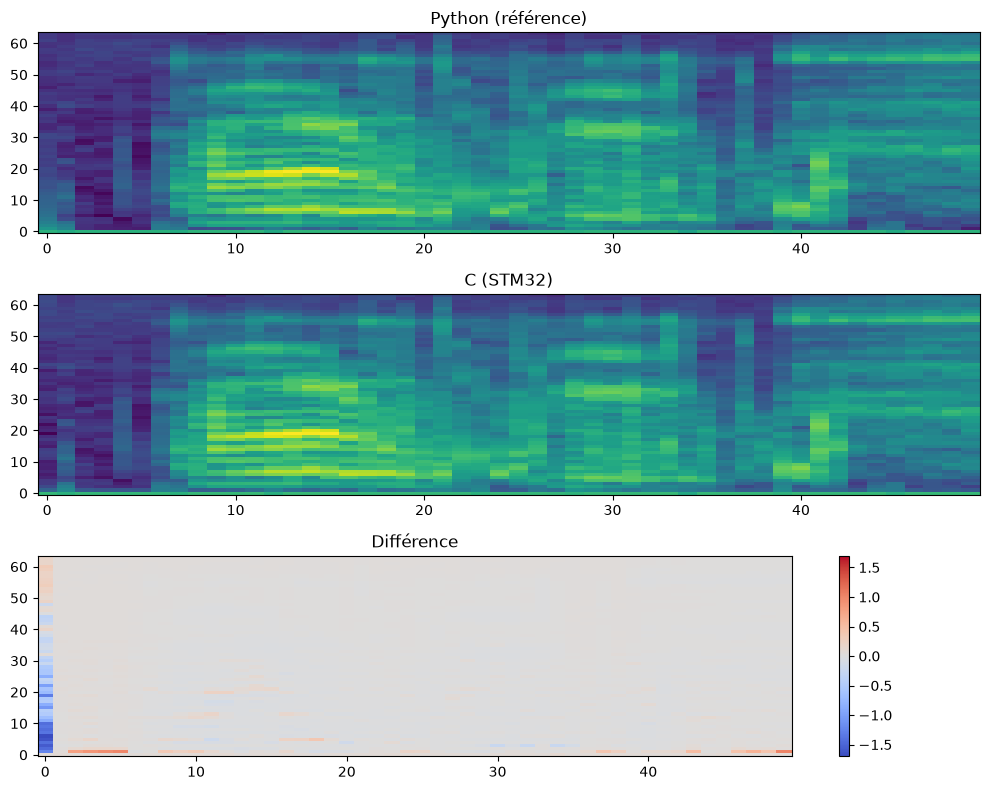

In [2]:
import matplotlib.pyplot as plt
import numpy as np

diff = log_mel_c - log_mel_ref
abs_diff = np.abs(diff)

# Où est le max exactement ?
idx_max = np.unravel_index(np.argmax(abs_diff), abs_diff.shape)
print(f"Erreur max localisée à : mel={idx_max[0]}, frame={idx_max[1]}")
print(f"Valeur C : {log_mel_c[idx_max]:.4f}, Valeur ref : {log_mel_ref[idx_max]:.4f}")

# Visualisation
fig, axes = plt.subplots(3, 1, figsize=(10, 8))
axes[0].imshow(log_mel_ref, aspect='auto', origin='lower'); axes[0].set_title("Python (référence)")
axes[1].imshow(log_mel_c, aspect='auto', origin='lower'); axes[1].set_title("C (STM32)")
im = axes[2].imshow(diff, aspect='auto', origin='lower', cmap='coolwarm', vmin=-1.7, vmax=1.7)
axes[2].set_title("Différence")
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.savefig("comparison.png")

# Distribution de l'erreur : combien de points dépassent un seuil ?
print(f"Points avec erreur > 0.5 : {(abs_diff > 0.5).sum()} / {abs_diff.size}")
print(f"Points avec erreur > 1.0 : {(abs_diff > 1.0).sum()} / {abs_diff.size}")

In [1]:
import librosa
print(librosa.__version__)

0.11.0


# Test avec zero pad inplace en C ; et comparaison avec les résultats en python

In [2]:
import numpy as np

log_mel_c = np.fromfile("/home/f24achba/Documents/Files_utils/test2_log_mel_out.bin", dtype=np.float32).reshape(64, 50)
log_mel_ref = np.loadtxt("log_mel_reference.csv", delimiter=",")

diff = log_mel_c - log_mel_ref
print(f"Erreur absolue max : {np.abs(diff).max():.6f}")
print(f"Erreur absolue moyenne : {np.abs(diff).mean():.6f}")
print(f"Corrélation : {np.corrcoef(log_mel_c.flatten(), log_mel_ref.flatten())[0,1]:.6f}")

Erreur absolue max : 0.996472
Erreur absolue moyenne : 0.014516
Corrélation : 0.998868
